In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')


pd.set_option('display.max_columns', None)

accounts  = pd.read_csv('accounts.csv')
txns      = pd.read_csv('transactions.csv')
merchants = pd.read_csv('merchants.csv')
reps      = pd.read_csv('field_reps.csv')
ab_test   = pd.read_csv('ab_test.csv')

print("accounts     :", len(accounts), "rows")
print("transactions :", len(txns), "rows")
print("merchants    :", len(merchants), "rows")
print("field_reps   :", len(reps), "rows")
print("ab_test      :", len(ab_test), "rows")

# ISSUE #1 — Duplicate account_id
print("Total rows in accounts   :", len(accounts))
print("Unique account_ids       :", accounts['account_id'].nunique())
print("Duplicate rows           :", len(accounts) - accounts['account_id'].nunique())
print()
print("The duplicate accounts:")
dupes = accounts[accounts.duplicated(subset='account_id', keep=False)]
print(dupes[['account_id','business_name','industry']].sort_values('account_id'))


# FIX for Issue #1 — keep first occurrence, drop duplicates
accounts_clean = accounts.drop_duplicates(subset='account_id', keep='first').reset_index(drop=True)

print("Before cleaning :", len(accounts), "rows")
print("After cleaning  :", len(accounts_clean), "rows")
print("Removed         :", len(accounts) - len(accounts_clean), "duplicate rows")
print()
print("All account_ids now unique:", accounts_clean['account_id'].nunique() == len(accounts_clean))

# ISSUE #2 — Mixed date formats
bad_format = txns[~txns['transaction_date'].str.match(r'^\d{4}-\d{2}-\d{2}$', na=False)]
print("Rows with wrong date format :", len(bad_format))
print("Sample bad dates:")
print(bad_format['transaction_date'].head(8).tolist())

# FIX for Issue #2 — parse both date formats
def parse_date(d):
    for fmt in ['%Y-%m-%d', '%m/%d/%Y']:
        try:
            return datetime.strptime(str(d), fmt)
        except:
            pass
    return None

txns['transaction_date'] = txns['transaction_date'].apply(parse_date)

print("Date conversion complete")
print("Unparseable dates remaining :", txns['transaction_date'].isna().sum())
print("Date column type            :", txns['transaction_date'].dtype)
print("Sample dates after fix:")
print(txns['transaction_date'].head(5).tolist())



NameError: name 'df' is not defined

In [17]:
# ISSUE #3 — Negative amounts (credits)
negatives = txns[txns['amount_usd'] < 0]

print("Negative amount rows     :", len(negatives))
print("Total credit value       : $", round(negatives['amount_usd'].sum(), 2))
print("Transaction types found  :")
print(negatives['transaction_type'].value_counts())
print()
print("Sample credit rows:")
print(negatives[['transaction_id','account_id','amount_usd','transaction_type']].head(5))


# FIX for Issue #3 — separate credits from spend
credits_df = txns[txns['amount_usd'] < 0].copy()
txns_spend = txns[txns['amount_usd'] > 0].copy()

print("Credit rows isolated     :", len(credits_df))
print("Spend rows remaining     :", len(txns_spend))
print("Total rows accounted for :", len(credits_df) + len(txns_spend))
print()
print("All amounts now positive :", (txns_spend['amount_usd'] < 0).sum() == 0)

Negative amount rows     : 25
Total credit value       : $ -27207.43
Transaction types found  :
transaction_type
CREDIT    25
Name: count, dtype: int64

Sample credit rows:
     transaction_id account_id  amount_usd transaction_type
52       TXN0000053    ACC0001     -704.71           CREDIT
486      TXN0000487    ACC0001    -1115.55           CREDIT
2205     TXN0002206    ACC0010    -1453.10           CREDIT
3852     TXN0003853    ACC0015    -1167.15           CREDIT
7407     TXN0007408    ACC0025     -701.99           CREDIT
Credit rows isolated     : 25
Spend rows remaining     : 84373
Total rows accounted for : 84398

All amounts now positive : True


In [18]:
# ISSUE #4 — NULL merchant_category
null_cat = txns_spend['merchant_category'].isna()

print("NULL merchant_category rows :", null_cat.sum())
print("As % of total transactions  :", round(null_cat.mean() * 100, 1), "%")
print("Dollar spend in NULL rows   : $", round(txns_spend[null_cat]['amount_usd'].sum(), 2))

NULL merchant_category rows : 300
As % of total transactions  : 0.4 %
Dollar spend in NULL rows   : $ 326528.78


In [20]:
# FIX for Issue #4 — fill NULL categories from merchants.csv
merch_cat_map = merchants.set_index('merchant_id')['merchant_category'].to_dict()

txns_spend['merchant_category'] = txns_spend.apply(
    lambda r: merch_cat_map.get(r['merchant_id'], r['merchant_category'])
    if pd.isna(r['merchant_category']) else r['merchant_category'],
    axis=1
)

txns_spend['merchant_category'] = txns_spend['merchant_category'].fillna('Unknown')

still_null = txns_spend['merchant_category'].isna().sum()
unknown    = (txns_spend['merchant_category'] == 'Unknown').sum()

print("NULL rows after fix      :", still_null)
print("Labeled as Unknown       :", unknown)
print("All categories filled    :", still_null == 0)


NULL rows after fix      : 0
Labeled as Unknown       : 0
All categories filled    : True


In [21]:
# ISSUE #5 — Reversed transactions
reversals = txns_spend[txns_spend['transaction_type'] == 'REVERSAL']
purchases = txns_spend[txns_spend['transaction_type'] == 'PURCHASE']

print("Total REVERSAL rows       :", len(reversals))
print("Total PURCHASE rows       :", len(purchases))
print("Dollar value of reversals : $", round(reversals['amount_usd'].sum(), 2))
print()
print("Sample reversal rows:")
print(reversals[['transaction_id','account_id','amount_usd','merchant_id','transaction_type']].head(5))

Total REVERSAL rows       : 150
Total PURCHASE rows       : 84223
Dollar value of reversals : $ 165001.14

Sample reversal rows:
      transaction_id account_id  amount_usd merchant_id transaction_type
83870     TXN0083871    ACC0235      962.98     MER0115         REVERSAL
83871     TXN0083872    ACC0185     1806.12     MER0122         REVERSAL
83872     TXN0083873    ACC0135      480.51     MER0100         REVERSAL
83873     TXN0083874    ACC0218      642.68     MER0126         REVERSAL
83874     TXN0083875    ACC0062     1450.19     MER0140         REVERSAL


In [24]:
# FIX for Issue #5 — remove reversals and their matching purchases
reversals = txns_spend[txns_spend['transaction_type'] == 'REVERSAL'].copy()
purchases = txns_spend[txns_spend['transaction_type'] == 'PURCHASE'].copy()

# Build a key: account + merchant + amount
reversals['_key'] = reversals['account_id'] + '|' + reversals['merchant_id'] + '|' + reversals['amount_usd'].astype(str)
purchases['_key'] = purchases['account_id'] + '|' + purchases['merchant_id'] + '|' + purchases['amount_usd'].astype(str)

# Find purchases that have a matching reversal
reversed_keys = set(reversals['_key'])
purchases_clean = purchases[~purchases['_key'].isin(reversed_keys)].drop(columns='_key')

print("Purchases before fix     :", len(purchases))
print("Matched purchases removed:", len(purchases) - len(purchases_clean))
print("Purchases after fix      :", len(purchases_clean))
print("Reversals removed        :", len(reversals))
print()
print("Total rows removed       :", (len(purchases) - len(purchases_clean)) + len(reversals))
print("Dollar amount cleaned    : $", round(reversals['amount_usd'].sum(), 2))

Purchases before fix     : 84223
Matched purchases removed: 150
Purchases after fix      : 84073
Reversals removed        : 150

Total rows removed       : 300
Dollar amount cleaned    : $ 165001.14


In [25]:
# ISSUE #6 — Multi-swipe transactions
purchases_sorted = purchases_clean.sort_values(
    ['account_id', 'merchant_id', 'amount_usd', 'transaction_date']
).copy()

purchases_sorted['_prev_dt'] = purchases_sorted.groupby(
    ['account_id', 'merchant_id', 'amount_usd']
)['transaction_date'].shift(1)

purchases_sorted['_mins_diff'] = (
    purchases_sorted['transaction_date'] - purchases_sorted['_prev_dt']
).dt.total_seconds() / 60

multi_swipe_mask = purchases_sorted['_mins_diff'] <= 120

print("Multi-swipe rows detected    :", multi_swipe_mask.sum())
print("Dollar value of multi-swipes : $", round(purchases_sorted[multi_swipe_mask]['amount_usd'].sum(), 2))

Multi-swipe rows detected    : 120
Dollar value of multi-swipes : $ 126596.66


In [26]:
# FIX for Issue #6 — remove multi-swipes, keep first transaction only
txns_clean = purchases_sorted[~multi_swipe_mask].drop(
    columns=['_prev_dt', '_mins_diff']
).reset_index(drop=True)

print("Purchases before fix  :", len(purchases_sorted))
print("Multi-swipes removed  :", multi_swipe_mask.sum())
print("Clean transactions    :", len(txns_clean))
print()
print("Total spend before    : $", round(purchases_sorted['amount_usd'].sum(), 2))
print("Total spend after     : $", round(txns_clean['amount_usd'].sum(), 2))
print("Inflated spend removed: $", round(purchases_sorted[multi_swipe_mask]['amount_usd'].sum(), 2))


Purchases before fix  : 84073
Multi-swipes removed  : 120
Clean transactions    : 83953

Total spend before    : $ 87932054.83
Total spend after     : $ 87805458.17
Inflated spend removed: $ 126596.66


In [27]:
# ISSUE #7 — Velocity burst detection
txns_clean['_hour'] = txns_clean['transaction_date'].dt.floor('h')

hourly_counts = txns_clean.groupby(
    ['account_id', '_hour']
).size().reset_index(name='txn_count')

velocity_flags = hourly_counts[hourly_counts['txn_count'] >= 10]

print("Accounts with velocity burst :", velocity_flags['account_id'].nunique())
print("Total burst-hour records     :", len(velocity_flags))
print()
print("Top 10 worst accounts:")
print(velocity_flags.nlargest(10, 'txn_count')[['account_id', '_hour', 'txn_count']])

Accounts with velocity burst : 20
Total burst-hour records     : 20

Top 10 worst accounts:
      account_id      _hour  txn_count
2062     ACC0011 2026-05-15         17
13215    ACC0062 2026-05-15         16
29647    ACC0138 2026-05-15         16
30878    ACC0143 2026-05-15         16
64865    ACC0299 2026-05-15         16
894      ACC0003 2026-05-15         14
32270    ACC0149 2026-05-15         14
46147    ACC0212 2026-05-15         14
59831    ACC0272 2026-05-15         14
62312    ACC0285 2026-05-15         14


In [28]:
# FIX for Issue #7 — flag velocity burst accounts, do not delete
burst_accounts = set(velocity_flags['account_id'].tolist())

txns_clean['velocity_flag'] = txns_clean['account_id'].isin(burst_accounts).astype(int)

print("Velocity flag added")
print("Transactions flagged :", txns_clean['velocity_flag'].sum())
print("Accounts flagged     :", txns_clean[txns_clean['velocity_flag']==1]['account_id'].nunique())
print()

# Clean up the helper column
txns_clean = txns_clean.drop(columns=['_hour'])
print("txns_clean is ready  :", len(txns_clean), "rows")

Velocity flag added
Transactions flagged : 3880
Accounts flagged     : 20

txns_clean is ready  : 83953 rows


In [33]:
# ISSUE #8 — A/B test pre-period imbalance
from scipy import stats

treatment = ab_test[ab_test['group'] == 'Treatment']['pre90_spend_usd']
control = ab_test[ab_test['group'] == 'Control']['pre90_spend_usd']

print(round(treatment.mean(), 2))
print(round(control.mean(), 2))

t_stat, p_val = stats.ttest_ind(treatment, control)
print(round(t_stat, 3))
print(round(p_val, 4))


if p_val < 0.05:
    print()
    print("WARNING: Groups are NOT balanced (p < 0.05)")
    print("Treatment accounts had higher baseline spend BEFORE the campaign")
    print("Raw lift estimate is biased — must flag this in analysis")
else:
    print("Groups are balanced (p >= 0.05)")

49468.87
31786.03
2.89
0.0043

Treatment accounts had higher baseline spend BEFORE the campaign
Raw lift estimate is biased — must flag this in analysis


In [39]:
# Q1 Step 1 - RFM calculation (copy-paste safe version)
snap = pd.Timestamp('2024-12-31')

col_date = 'transaction_date'
col_id = 'transaction_id'
col_amt = 'amount_usd'
col_acc = 'account_id'

r = txns_clean.groupby(col_acc)[col_date].max().reset_index()
r.columns = ['account_id', 'last_txn']
r['R_days'] = (snap - r['last_txn']).dt.days

f = txns_clean.groupby(col_acc)[col_id].count().reset_index()
f.columns = ['account_id', 'F_count']

                                                                                           

In [41]:
m = txns_clean.groupby(col_acc)[col_amt].sum().reset_index()
m.columns = ['account_id', 'M_total']


rfm = r[['account_id', 'R_days']].merge(f, on='account_id')
rfm = rfm.merge(m, on='account_id')
print("Shape:", rfm.shape)
print(rfm.head()) 

Shape: (300, 4)
  account_id  R_days  F_count     M_total
0    ACC0001    -544     1091  1299523.34
1    ACC0002    -544       85    64083.65
2    ACC0003    -542      165   146349.33
3    ACC0004    -539      134    87256.05
4    ACC0005    -540       61    52396.27


In [46]:
c1 = 'account_id'
c2 = 'transaction_date'
c3 = 'transaction_id'
c4 = 'amount_usd'

snap = txns_clean[c2].max() + pd.Timedelta(days=1)
r = txns_clean.groupby(c1)[c2].max().reset_index()
r.columns = [c1, 'last_txn']
r['R_days'] = (snap - r['last_txn']).dt.days

In [47]:
f = txns_clean.groupby(c1)[c3].count().reset_index()
f.columns = [c1, 'F_count']
m = txns_clean.groupby(c1)[c4].sum().reset_index()
m.columns = [c1, 'M_total']

In [48]:
rfm = r[[c1, 'R_days']].merge(f, on=c1)
rfm = rfm.merge(m, on=c1)
print(rfm.shape)
print(rfm.head())

(300, 4)
  account_id  R_days  F_count     M_total
0    ACC0001       1     1091  1299523.34
1    ACC0002       1       85    64083.65
2    ACC0003       3      165   146349.33
3    ACC0004       6      134    87256.05
4    ACC0005       5       61    52396.27


In [50]:
rfm['R_score'] = pd.qcut(rfm['R_days'], 5, labels=False, duplicates='drop')
rfm['F_score'] = pd.qcut(rfm['F_count'], 5, labels=False, duplicates='drop')
rfm['M_score'] = pd.qcut(rfm['M_total'], 5, labels=False, duplicates='drop')
rfm['RFM'] = rfm['R_score'].fillna(0) + rfm['F_score'].fillna(0) + rfm['M_score'].fillna(0)
print(rfm[['account_id','R_score','F_score','M_score','RFM']].head(10))
print(rfm['RFM'].describe())

  account_id  R_score  F_score  M_score  RFM
0    ACC0001        0        4        4    8
1    ACC0002        0        0        0    0
2    ACC0003        1        2        2    5
3    ACC0004        2        1        1    4
4    ACC0005        2        0        0    2
5    ACC0006        0        0        0    0
6    ACC0007        0        0        0    0
7    ACC0008        3        2        2    7
8    ACC0009        1        2        2    5
9    ACC0010        0        4        4    8
count    300.000000
mean       5.066667
std        2.518604
min        0.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       11.000000
Name: RFM, dtype: float64


In [51]:
def tier(score):
    if score >= 8:
        return 'Tier 1 - Champions'
    elif score >= 4:
        return 'Tier 2 - Actives'
    else:
        return 'Tier 3 - At Risk'

rfm['segment'] = rfm['RFM'].apply(tier)
print(rfm['segment'].value_counts())

segment
Tier 2 - Actives      148
Tier 3 - At Risk       86
Tier 1 - Champions     66
Name: count, dtype: int64


In [52]:
rfm2 = rfm.merge(accounts_clean, on='account_id')
profile = rfm2.groupby('segment').agg(
    count=('account_id', 'count'),
    avg_spend=('M_total', 'mean'),
    avg_freq=('F_count', 'mean'),
    avg_recency=('R_days', 'mean')
).round(0)
print(profile)

                    count  avg_spend  avg_freq  avg_recency
segment                                                    
Tier 1 - Champions     66   755250.0     614.0          3.0
Tier 2 - Actives      148   212086.0     232.0          4.0
Tier 3 - At Risk       86    76398.0     106.0          4.0


In [53]:
ind = rfm2.groupby(['segment','industry']).size().unstack(fill_value=0)
print(ind)


industry            Construction  Healthcare  Logistics  Manufacturing  \
segment                                                                  
Tier 1 - Champions             4          10          4              4   
Tier 2 - Actives              24          16          5              4   
Tier 3 - At Risk              10           9          1              5   

industry            Professional Services  Restaurants  Retail  Technology  
segment                                                                     
Tier 1 - Champions                      8            7      12          17  
Tier 2 - Actives                       22           18      29          30  
Tier 3 - At Risk                       19            7      15          20  


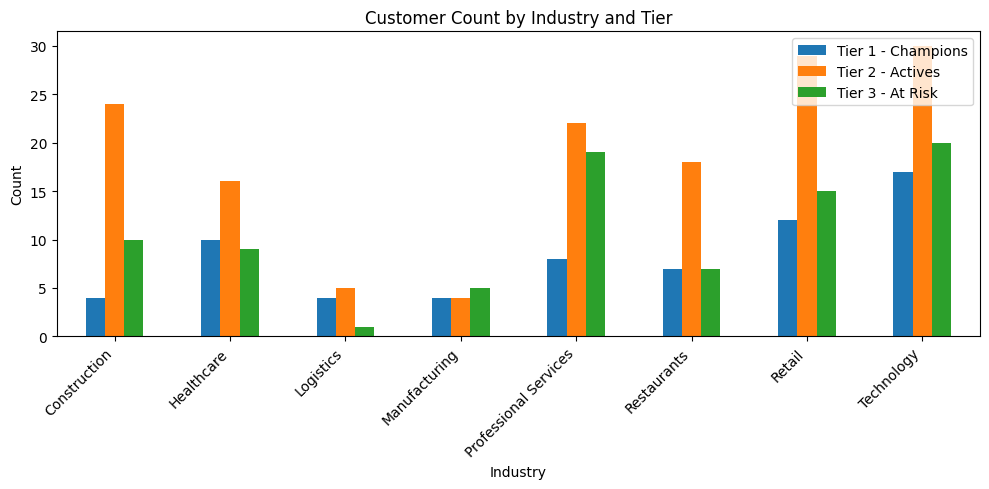

In [54]:
ind.T.plot(kind='bar', figsize=(10,5))
plt.title('Customer Count by Industry and Tier')
plt.xlabel('Industry')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
